# Validating and Analyzing SIPRI Military Expenditure Data

### **Author:** Angel Morenu
### Data Science Project

## Project objective

A reproducible workflow that loads military expenditure data,
checks record quality, calculates country-level statistics for 2025,
measures growth in worldwide expenditure, and generates a distribution
chart using observed country records.

## Plain-language description

This notebook checks a public military-spending dataset for invalid
years, invalid spending values, and duplicate country-year records.
It separates country observations from aggregate or unclassified records
before calculating statistics.

The outputs include a validation summary, descriptive statistics,
the ten highest-spending countries, worldwide growth between the first
and last valid observed years, and a chart showing the distribution of
country spending.

## Data source and assumptions

- Input: `military-spending-sipri.csv` or a ZIP containing that CSV.
- Source: SIPRI military expenditure data, distributed via Our World in Data.
- The source series is expressed in constant 2024 US dollars; retain that
  unit when interpreting the results.
- Results are calculated when the notebook runs; no results are hard-coded.

**Reference supplied with the project:** SIPRI, *Trends in World Military
Expenditure, 2025*, April 2026.
https://doi.org/10.55163/ZLHQ1057

## 1. Import libraries and define constants

**Environment:** Python 3.9 or later with NumPy, pandas, Matplotlib,
and IPython installed.

In [154]:
from __future__ import annotations

import math
import warnings
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import pandas as pd
from IPython.display import Image, display

REQUIRED_COLUMNS = {"Entity", "Year", "Military expenditure"}
COUNTRY_CODE_PATTERN = r"^[A-Z]{3}$"

## 2. Configure input and output paths

This cell replaces the original script's command-line arguments.
Place the input file beside the notebook or update `INPUT_PATH`.

Set `SAMPLE_STD` to `False` to use population standard deviation.

In [155]:
INPUT_PATH = Path("military-spending-sipri.csv")
# Alternative:
# INPUT_PATH = Path("military-spending-sipri.zip")

OUTPUT_CHART = Path("outputs/military_expenditure_distribution_2025.png")
SAMPLE_STD = True

print(f"Working directory: {Path.cwd()}")
print(f"Input file: {INPUT_PATH.resolve()}")
print(f"Chart output: {OUTPUT_CHART.resolve()}")
print(
    "Standard deviation:",
    "sample (ddof=1)" if SAMPLE_STD else "population (ddof=0)"
)

Working directory: /Users/angelhdbaez/Desktop/Validating-International-Military-Expenditure-Data-with-Python
Input file: /Users/angelhdbaez/Desktop/Validating-International-Military-Expenditure-Data-with-Python/military-spending-sipri.csv
Chart output: /Users/angelhdbaez/Desktop/Validating-International-Military-Expenditure-Data-with-Python/outputs/military_expenditure_distribution_2025.png
Standard deviation: sample (ddof=1)


## 3. Define the input loader

The loader accepts CSV and ZIP files. For ZIP input, it prefers
`military-spending-sipri.csv`; otherwise it uses the first CSV found.

In [156]:
def load_input(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Input file not found: {path}")

    if path.suffix.lower() == ".zip":
        with ZipFile(path) as archive:
            candidates = [
                name for name in archive.namelist()
                if name.lower().endswith(".csv")
            ]
            if not candidates:
                raise ValueError("ZIP file does not contain a CSV file.")

            target = None
            for name in candidates:
                if Path(name).name == "military-spending-sipri.csv":
                    target = name
                    break

            if target is None:
                target = candidates[0]

            with archive.open(target) as csv_file:
                return pd.read_csv(csv_file)

    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)

    raise ValueError("Input must be a CSV file or a ZIP containing a CSV file.")

### Load and preview the source records

In [157]:
raw = load_input(INPUT_PATH)

print(f"Loaded {len(raw):,} rows and {len(raw.columns)} columns.")
print(f"Columns: {list(raw.columns)}")
display(raw.head())

Loaded 9,112 rows and 5 columns.
Columns: ['Entity', 'Code', 'Year', 'Military expenditure', 'World region according to OWID']


,Entity,Code,Year,Military expenditure,World region according to OWID
0,Afghanistan,AFG,1970,5373185.0,Asia
1,Afghanistan,AFG,1973,6230685.0,Asia
2,Afghanistan,AFG,1974,6056124.0,Asia
3,Afghanistan,AFG,1975,6357396.0,Asia
4,Afghanistan,AFG,1976,8108200.0,Asia


## 4. Define data validation and preparation

Records are flagged for invalid years, invalid expenditure, and duplicate
country-year combinations.

A three-uppercase-letter code is used as a **country-classification
heuristic**, not a verified country registry. Records that do not match
are treated as aggregate/non-country records for this analysis, but may
also include countries with missing or nonstandard codes.

Duplicate country-year checks use the entity name and year. Every member
of a duplicate group is excluded from country analysis.

In [158]:
def validate_and_prepare(
    raw: pd.DataFrame,
) -> tuple[pd.DataFrame, dict[str, int]]:
    missing_columns = REQUIRED_COLUMNS - set(raw.columns)
    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    df = raw.copy()

    year_numeric = pd.to_numeric(df["Year"], errors="coerce")
    year_is_whole_number = (
        year_numeric.notna()
        & np.isfinite(year_numeric)
        & (year_numeric % 1 == 0)
    )

    spending_numeric = pd.to_numeric(
        df["Military expenditure"], errors="coerce"
    )
    spending_is_finite = (
        spending_numeric.notna() & np.isfinite(spending_numeric)
    )
    spending_is_non_negative = spending_numeric >= 0

    df["year_numeric"] = year_numeric
    df["spending_numeric"] = spending_numeric
    df["year_invalid"] = ~year_is_whole_number
    df["spending_invalid"] = ~(
        spending_is_finite & spending_is_non_negative
    )

    df.loc[year_is_whole_number, "year_int"] = (
        year_numeric[year_is_whole_number].astype(int)
    )

    codes = df.get(
        "Code", pd.Series(index=df.index, dtype="object")
    )
    df["is_country"] = (
        codes.fillna("").astype(str).str.match(COUNTRY_CODE_PATTERN)
    )

    duplicate_country_year = (
        df[df["is_country"] & ~df["year_invalid"]]
        .duplicated(subset=["Entity", "year_int"], keep=False)
        .reindex(df.index, fill_value=False)
    )
    df["duplicate_country_year"] = duplicate_country_year

    summary = {
        "total_rows": int(len(df)),
        "invalid_year_rows": int(df["year_invalid"].sum()),
        "invalid_spending_rows": int(df["spending_invalid"].sum()),
        "duplicate_country_year_rows": int(
            df["duplicate_country_year"].sum()
        ),
        "aggregate_rows": int((~df["is_country"]).sum()),
    }

    return df, summary

## 5. Run validation and review flagged records

Counts below cover **all years in the input**, not only 2025.
Flag counts can overlap and should not be added together as unique
excluded-record counts.

In [159]:
df, validation_summary = validate_and_prepare(raw)

included_mask = (
    df["is_country"]
    & ~df["year_invalid"]
    & ~df["spending_invalid"]
    & ~df["duplicate_country_year"]
)

included_rows = int(included_mask.sum())
excluded_rows = int(len(df) - included_rows)

print("VALIDATION SUMMARY")
print("-" * 72)
print(f"Total rows reviewed: {validation_summary['total_rows']:,}")
print(
    f"Rows with invalid year values: "
    f"{validation_summary['invalid_year_rows']:,}"
)
print(
    f"Rows with invalid expenditure values: "
    f"{validation_summary['invalid_spending_rows']:,}"
)
print(
    f"Rows with duplicate country-year: "
    f"{validation_summary['duplicate_country_year_rows']:,}"
)
print(
    f"Aggregate/non-country rows excluded from country analysis: "
    f"{validation_summary['aggregate_rows']:,}"
)
print(f"Included rows for country analysis: {included_rows:,}")
print(f"Excluded rows from country analysis: {excluded_rows:,}")

VALIDATION SUMMARY
------------------------------------------------------------------------
Total rows reviewed: 9,112
Rows with invalid year values: 0
Rows with invalid expenditure values: 0
Rows with duplicate country-year: 0
Aggregate/non-country rows excluded from country analysis: 771
Included rows for country analysis: 8,341
Excluded rows from country analysis: 771


In [160]:
flagged_mask = (
    df["year_invalid"]
    | df["spending_invalid"]
    | df["duplicate_country_year"]
)

review_columns = [
    column for column in [
        "Entity", "Code", "Year", "Military expenditure",
        "year_invalid", "spending_invalid", "duplicate_country_year"
    ]
    if column in df.columns
]

flagged_records = df.loc[flagged_mask, review_columns]

print(f"Unique records flagged for review: {len(flagged_records):,}")
display(flagged_records.head(20))

if "Code" not in raw.columns:
    print(
        "WARNING: The Code column is absent. "
        "The country-classification heuristic cannot identify countries."
    )

Unique records flagged for review: 0


,Entity,Code,Year,Military expenditure,year_invalid,spending_invalid,duplicate_country_year


## 6. Define 2025 country statistics

Calculate the mean, median, and standard deviation from eligible
2025 observations, and identify the ten largest expenditures.

In [161]:
def compute_country_2025_stats(
    df: pd.DataFrame,
    sample_std: bool,
) -> tuple[pd.DataFrame, dict[str, float]]:
    valid_country_rows = df[
        df["is_country"]
        & ~df["year_invalid"]
        & ~df["spending_invalid"]
        & ~df["duplicate_country_year"]
    ].copy()

    subset_2025 = valid_country_rows[
        valid_country_rows["year_int"] == 2025
    ].copy()

    if subset_2025.empty:
        raise ValueError("No valid country rows found for year 2025.")

    spend = subset_2025["spending_numeric"]
    std_ddof = 1 if sample_std else 0

    stats = {
        "country_count": float(len(subset_2025)),
        "mean": float(spend.mean()),
        "median": float(spend.median()),
        "std": float(spend.std(ddof=std_ddof)),
        "std_ddof": float(std_ddof),
    }

    top_10 = (
        subset_2025
        .sort_values("spending_numeric", ascending=False)
        .head(10)
    )

    return top_10, stats

## 7. Display the 2025 summary and top ten countries

Monetary results are shown in the source variable's units.
If sample standard deviation is selected and only one eligible
observation exists, its standard deviation is undefined.

In [162]:
top_10, stats = compute_country_2025_stats(
    df, sample_std=SAMPLE_STD
)

std_kind = "sample" if int(stats["std_ddof"]) == 1 else "population"

print("2025 COUNTRY SUMMARY (calculated from observed records)")
print("-" * 72)
print(f"Country count: {stats['country_count']:.0f}")
print(f"Mean expenditure: ${stats['mean'] / 1e9:,.3f} billion")
print(f"Median expenditure: ${stats['median'] / 1e9:,.3f} billion")
print(
    f"Standard deviation ({std_kind}, ddof={int(stats['std_ddof'])}): "
    f"${stats['std'] / 1e9:,.3f} billion"
)

2025 COUNTRY SUMMARY (calculated from observed records)
------------------------------------------------------------------------
Country count: 150
Mean expenditure: $18.266 billion
Median expenditure: $1.285 billion
Standard deviation (sample, ddof=1): $82.608 billion


In [163]:
top_10_table = (
    top_10[["Entity", "spending_numeric"]]
    .rename(columns={
        "Entity": "Country",
        "spending_numeric": "Military expenditure",
    })
    .reset_index(drop=True)
)

print("TOP 10 COUNTRIES BY 2025 EXPENDITURE")
print("-" * 72)
display(
    top_10_table.style.format({
        "Military expenditure": "{:,.2f}"
    })
)

TOP 10 COUNTRIES BY 2025 EXPENDITURE
------------------------------------------------------------------------


,Country,Military expenditure
0,United States,"929,162,850,000.00"
1,China,"335,017,640,000.00"
2,Russia,"158,236,360,000.00"
3,Germany,"106,727,250,000.00"
4,India,"93,254,680,000.00"
5,United Kingdom,"87,984,550,000.00"
6,Saudi Arabia,"81,470,690,000.00"
7,Ukraine,"77,555,890,000.00"
8,France,"64,515,090,000.00"
9,Japan,"59,493,143,000.00"


## 8. Define worldwide growth calculations

Growth is measured between the **first and last valid World observations
in the input**, which may differ from the presentation's 1998–2025 period.

This preserves the original script's duplicate handling: for a duplicated
World year, the last valid record in input order is retained. This policy
is not a verification that the retained record is authoritative.

The calculation uses endpoint values and elapsed calendar years;
it does not require uninterrupted annual coverage.

Percentage growth:

`((last value - first value) / first value) × 100`

Compound annual growth rate (CAGR):

`(last value / first value) ** (1 / elapsed years) - 1`

In [164]:
def compute_world_growth(df: pd.DataFrame) -> dict[str, float]:
    world = df[
        df["Entity"].eq("World")
        & ~df["year_invalid"]
        & ~df["spending_invalid"]
    ][["year_int", "spending_numeric"]].copy()

    if world.empty:
        raise ValueError("No valid World rows found for growth calculation.")

    # Stable sorting makes the input-order duplicate policy explicit.
    world = world.sort_values("year_int", kind="stable")
    world = world.drop_duplicates(subset=["year_int"], keep="last")

    first_year = int(world.iloc[0]["year_int"])
    last_year = int(world.iloc[-1]["year_int"])
    first_value = float(world.iloc[0]["spending_numeric"])
    last_value = float(world.iloc[-1]["spending_numeric"])

    if first_value <= 0:
        raise ValueError(
            "Cannot compute growth rates when first World value is <= 0."
        )

    elapsed_years = last_year - first_year
    if elapsed_years <= 0:
        raise ValueError("Cannot compute CAGR when elapsed years is 0.")

    pct_growth = ((last_value - first_value) / first_value) * 100
    cagr = (last_value / first_value) ** (1 / elapsed_years) - 1

    return {
        "first_year": float(first_year),
        "last_year": float(last_year),
        "first_value": first_value,
        "last_value": last_value,
        "percent_growth": pct_growth,
        "cagr": cagr,
    }

## 9. Review World duplicates and display growth

In [165]:
valid_world = df[
    df["Entity"].eq("World")
    & ~df["year_invalid"]
    & ~df["spending_invalid"]
]

world_duplicates = valid_world[
    valid_world.duplicated("year_int", keep=False)
]

if not world_duplicates.empty:
    print(
        "WARNING: Duplicate valid World years were found. "
        "The calculation retains the last valid input record per year."
    )
    display(
        world_duplicates[
            ["Entity", "Year", "Military expenditure"]
        ]
    )

world_1991_raw = raw[
    raw["Entity"].eq("World") & raw["Year"].eq(1991)
]
world_1991_valid = valid_world[valid_world["year_int"].eq(1991)]
if world_1991_raw.empty:
    print(
        "1991 World record status: absent from the source data; "
        "it was not excluded by validation."
    )
elif world_1991_valid.empty:
    print(
        "1991 World record status: present in the source but excluded "
        "by validation."
    )
else:
    print("1991 World record status: present and valid.")

growth = compute_world_growth(df)

print("WORLD GROWTH FROM FIRST TO LAST OBSERVED YEAR")
print("-" * 72)
print(
    f"{int(growth['first_year'])} to {int(growth['last_year'])}: "
    f"{growth['first_value']:,.2f} -> {growth['last_value']:,.2f}"
)
print(f"Percentage growth: {growth['percent_growth']:.2f}%")
print(
    f"Compound annual growth rate (CAGR): "
    f"{growth['cagr'] * 100:.2f}%"
)

1991 World record status: absent from the source data; it was not excluded by validation.
WORLD GROWTH FROM FIRST TO LAST OBSERVED YEAR
------------------------------------------------------------------------
1988 to 2025: 1,759,879,600,000.00 -> 2,771,294,000,000.00
Percentage growth: 57.47%
Compound annual growth rate (CAGR): 1.23%


## 10. World military expenditure over time

This line chart uses observed valid World values in constant 2024 U.S. dollars.
Years with no observation remain gaps rather than being interpolated.

Data coverage note: No valid World observation for 1991. The chart preserves gaps; no interpolation was performed.
Chart saved to: outputs/world_military_expenditure_over_time.png


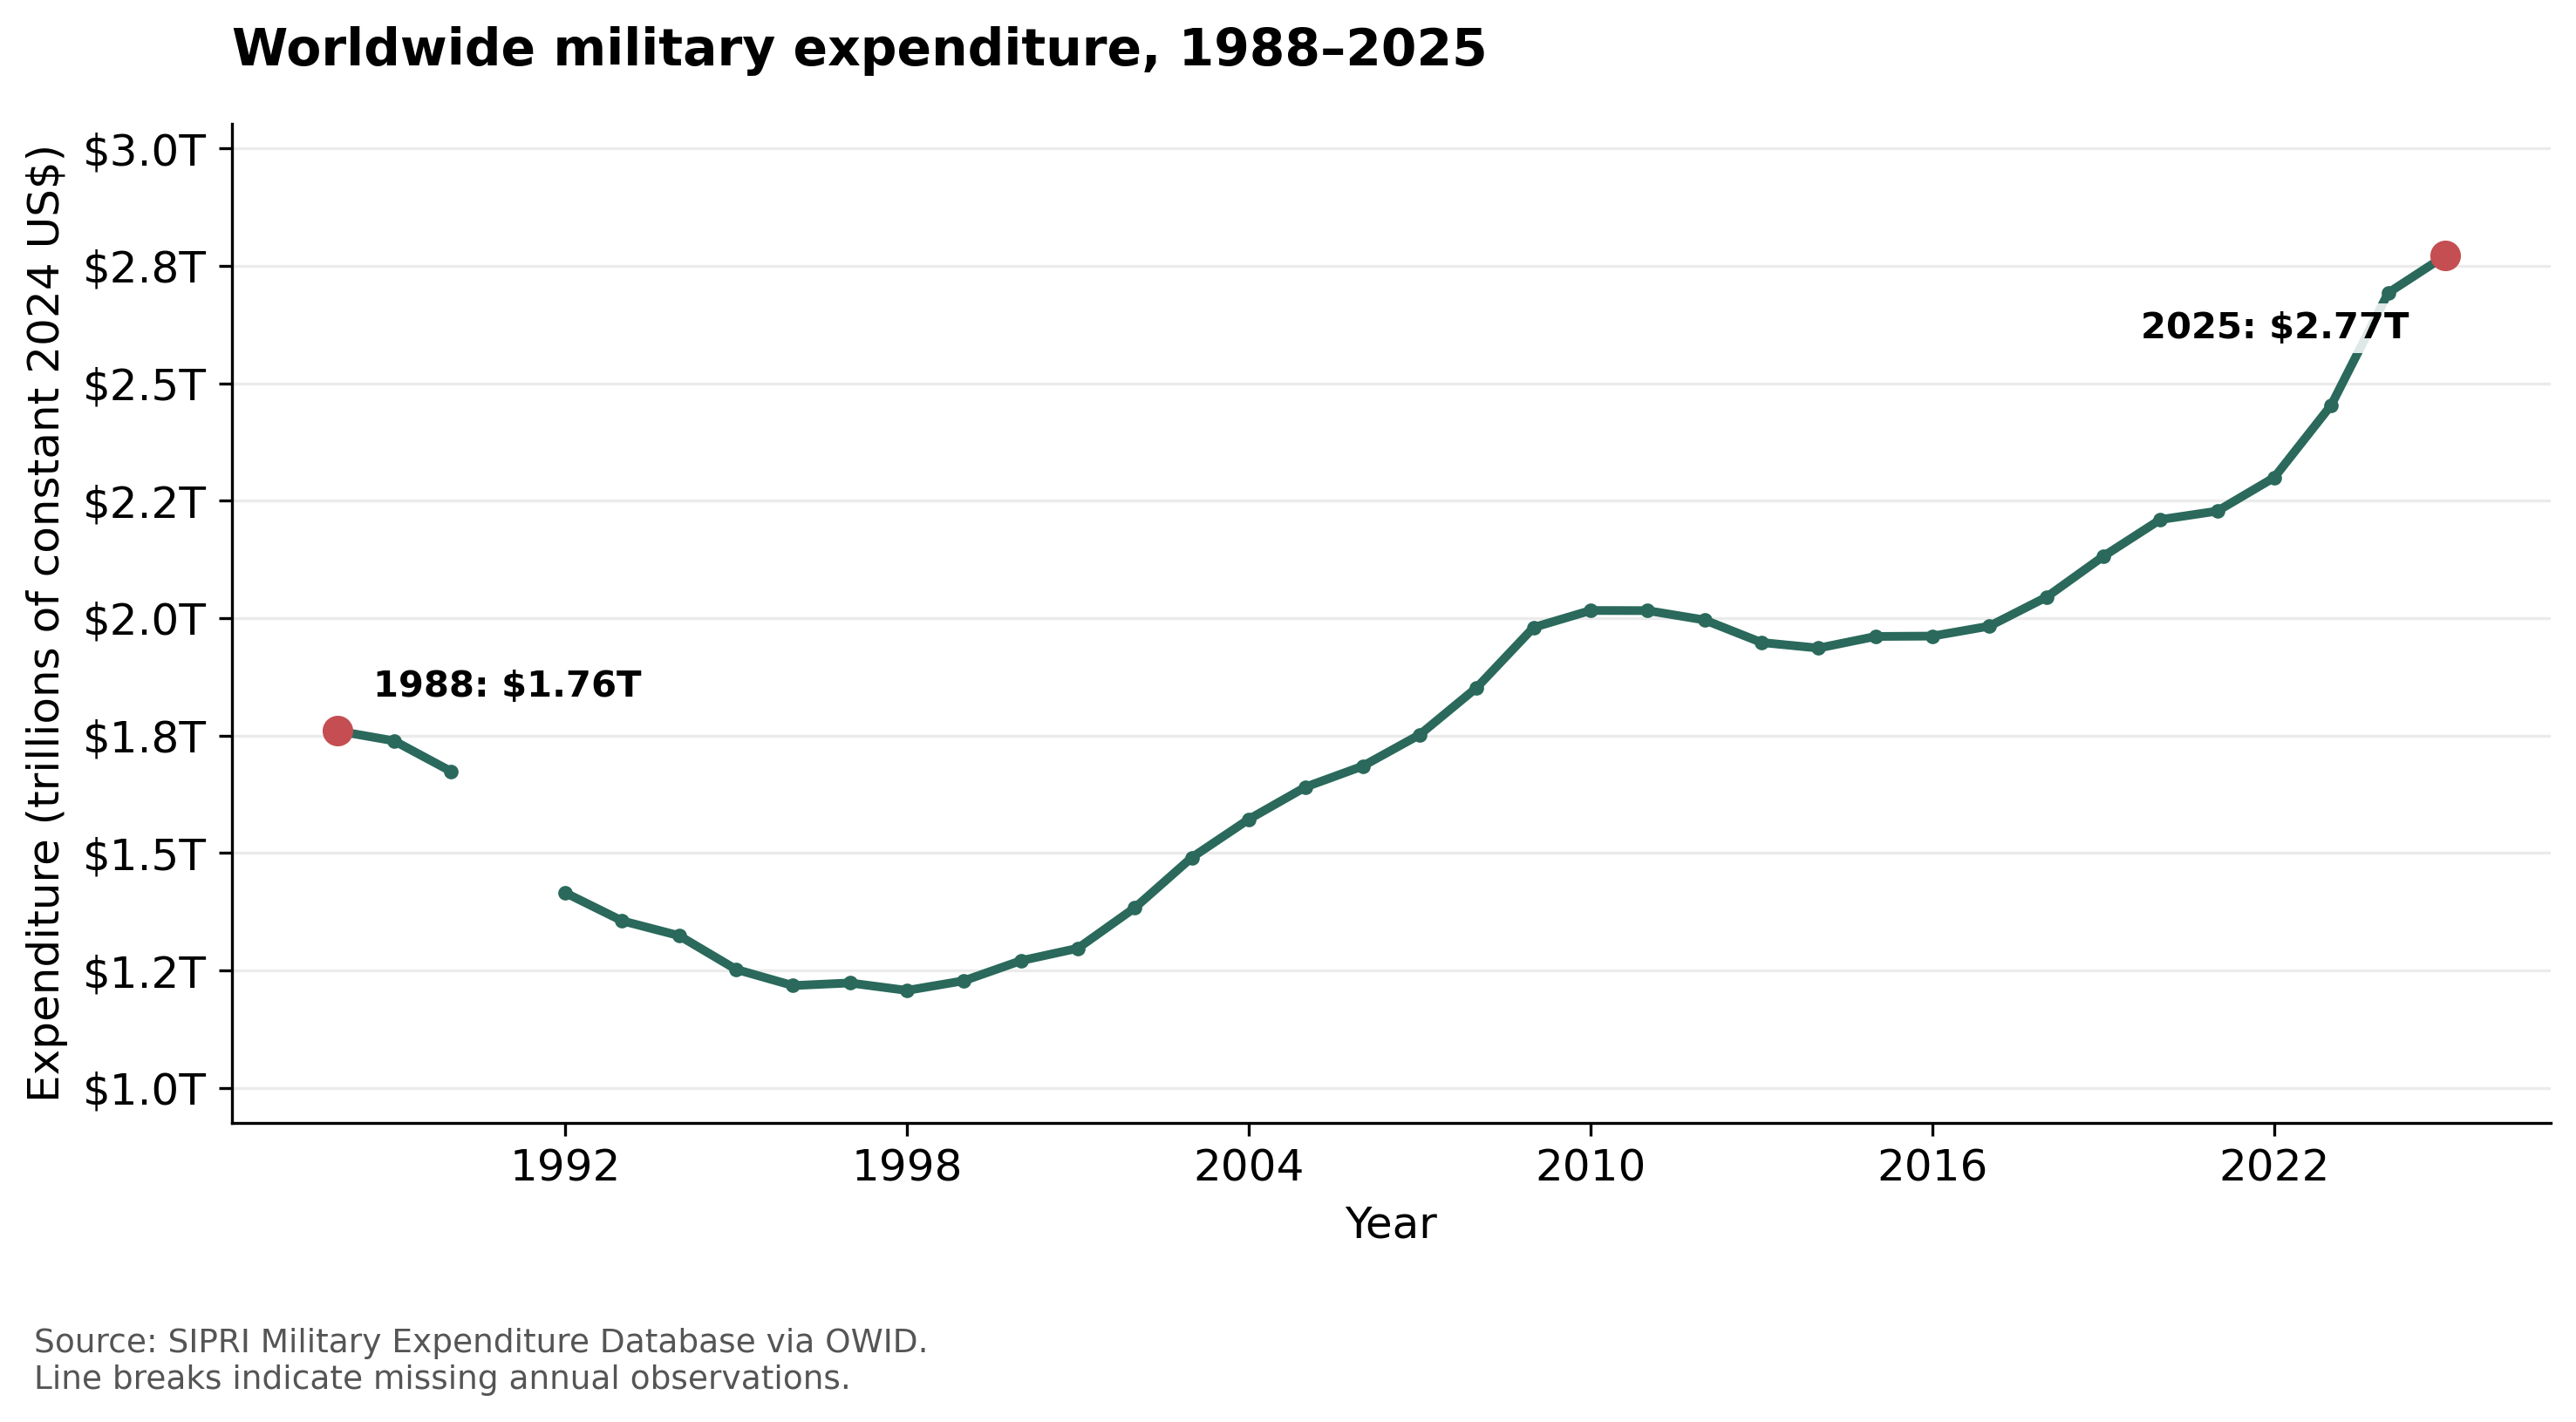

In [180]:
def create_world_trend_chart(
    df: pd.DataFrame,
    output_chart: Path,
    *,
    duplicate_policy: str = "error",
    price_basis: str = "constant 2024 US$",
) -> None:
    """Plot valid World observations without interpolating missing years.

    duplicate_policy:
        "error" — reject duplicate valid World years (default).
        "last"  — warn and retain the last valid input record per year.

    Verify price_basis against the source metadata before publication.
    """
    required = {
        "Entity",
        "year_invalid",
        "spending_invalid",
        "year_int",
        "spending_numeric",
    }
    missing_columns = required.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"DataFrame is missing required columns: {sorted(missing_columns)}"
        )

    if duplicate_policy not in {"error", "last"}:
        raise ValueError("duplicate_policy must be 'error' or 'last'.")

    output_chart = Path(output_chart)

    valid_mask = (
        df["Entity"].eq("World")
        & ~df["year_invalid"].fillna(True)
    )

    if duplicate_policy not in {"error", "last"}:
        raise ValueError("duplicate_policy must be 'error' or 'last'.")

    output_chart = Path(output_chart)

    valid_mask = (
        df["Entity"].eq("World")
        & ~df["year_invalid"].fillna(True)
        & ~df["spending_invalid"].fillna(True)
    )
    world = df.loc[
        valid_mask, ["year_int", "spending_numeric"]
    ].copy()

    if world.empty:
        raise ValueError("No valid World rows available for trend chart.")

    # Recheck the selected values before converting or plotting.
    years = pd.to_numeric(world["year_int"], errors="coerce")
    spending = pd.to_numeric(world["spending_numeric"], errors="coerce")

    valid_values = (
        years.notna()
        & np.isfinite(years)
        & years.mod(1).eq(0)
        & spending.notna()
        & np.isfinite(spending)
        & spending.ge(0)
    )
    if not valid_values.all():
        raise ValueError(
            "Selected World rows contain invalid years or expenditure "
            "despite their validation flags."
        )

    world["year_int"] = years.astype("int64")
    world["spending_numeric"] = spending.astype(float)

    duplicate_mask = world.duplicated("year_int", keep=False)
    if duplicate_mask.any():
        duplicate_rows = world.loc[duplicate_mask].sort_values(
            "year_int", kind="stable"
        )
        message = (
            "Duplicate valid World years found:\n"
            + duplicate_rows.to_string(index=False)
        )

        if duplicate_policy == "error":
            raise ValueError(message)

        warnings.warn(
            message + "\nRetaining the last valid input record per year.",
            UserWarning,
            stacklevel=2,
        )
        world = world.drop_duplicates("year_int", keep="last")

    world = world.sort_values("year_int", kind="stable")

    if len(world) < 2:
        raise ValueError("At least two observed years are required.")

    first_year = int(world.iloc[0]["year_int"])
    last_year = int(world.iloc[-1]["year_int"])

    # Missing annual observations remain NaN, creating visible line breaks.
    annual = (
        world.set_index("year_int")["spending_numeric"]
        .reindex(range(first_year, last_year + 1))
    )
    missing_years = annual.index[annual.isna()].tolist()

    if missing_years:
        missing_year_text = ", ".join(map(str, missing_years))
        print(
            f"Data coverage note: No valid World observation for "
            f"{missing_year_text}. The chart preserves gaps; "
            "no interpolation was performed."
        )

    trillions = annual / 1e12
    endpoints = trillions.loc[[first_year, last_year]]

    fig, ax = plt.subplots(figsize=(10, 5.5))

    try:
        ax.plot(
            trillions.index,
            trillions.values,
            color="#2A695B",
            linewidth=2.4,
            marker="o",
            markersize=3,
            zorder=2,
        )
        ax.scatter(
            endpoints.index,
            endpoints.values,
            color="#C44E52",
            s=55,
            zorder=3,
        )

        for year, value, offset, alignment in [
            (first_year, endpoints.iloc[0], (10, 12), "left"),
            (last_year, endpoints.iloc[-1], (-10, -20), "right"),
        ]:
            ax.annotate(
                f"{year}: ${value:.2f}T",
                xy=(year, value),
                xytext=offset,
                textcoords="offset points",
                ha=alignment,
                va="center",
                fontsize=10,
                fontweight="bold",
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.85,
                    "pad": 2,
                },
            )

        ax.set_title(
            f"Worldwide military expenditure, {first_year}–{last_year}",
            loc="left",
            fontsize=14,
            fontweight="bold",
            pad=16,
        )
        ax.set_xlabel("Year")
        ax.set_ylabel(f"Expenditure (trillions of {price_basis})")

        ax.xaxis.set_major_locator(
            MaxNLocator(nbins=8, integer=True)
        )
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda value, _: f"${value:.1f}T")
        )
        ax.margins(x=0.05, y=0.18)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

        note = "Source: SIPRI Military Expenditure Database via OWID."
        if missing_years:
            note += "\nLine breaks indicate missing annual observations."

        fig.text(
            0.02, 0.02, note, fontsize=9, color="#555555"
        )
        fig.tight_layout(rect=(0, 0.09, 1, 1))

        output_chart.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_chart, dpi=300, bbox_inches="tight")
    finally:
        plt.close(fig)


WORLD_TREND_CHART = Path(
    "outputs/world_military_expenditure_over_time.png"
)

create_world_trend_chart(
    df,
    WORLD_TREND_CHART,
    duplicate_policy="error",
)

print(f"Chart saved to: {WORLD_TREND_CHART.as_posix()}")
display(Image(filename=str(WORLD_TREND_CHART)))

## 10. Define the observed-data distribution chart

The histogram uses actual eligible 2025 expenditures rather than
a theoretical fitted distribution.

The spending axis and bin boundaries are logarithmic. Zero expenditures
remain eligible for descriptive statistics but are omitted from this
chart because zero cannot be plotted on a logarithmic axis.

In [167]:
def create_distribution_chart(
    df: pd.DataFrame,
    output_chart: Path,
) -> None:
    subset_2025 = df[
        df["is_country"]
        & ~df["year_invalid"]
        & ~df["spending_invalid"]
        & ~df["duplicate_country_year"]
        & df["year_int"].eq(2025)
    ].copy()

    values = subset_2025["spending_numeric"]
    positive_values = values[values > 0]

    if positive_values.empty:
        raise ValueError(
            "No positive 2025 country values available for charting."
        )

    lower = float(positive_values.min())
    upper = float(positive_values.max())

    # Avoid identical bin edges when all positive values are equal.
    if lower == upper:
        lower /= 10
        upper *= 10

    bins = np.logspace(
        math.log10(lower), math.log10(upper), 25
    )

    # Ensure floating-point rounding does not exclude either endpoint.
    bins[0] = min(bins[0], float(positive_values.min()))
    bins[-1] = max(bins[-1], float(positive_values.max()))

    fig, ax = plt.subplots(figsize=(10, 5.5))

    ax.hist(
        positive_values,
        bins=bins,
        color="#4C78A8",
        edgecolor="white",
        alpha=0.9,
    )
    ax.set_xscale("log")
    ax.set_title("Distribution of 2025 country military expenditure")
    ax.set_xlabel(
        "Military expenditure (constant 2024 US$, logarithmic scale)"
    )
    ax.set_ylabel("Number of countries")
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    output_chart.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_chart, dpi=300)
    plt.close(fig)

## 11. Generate, save, and display the chart

Zero-expenditure records omitted from the logarithmic chart: 3
Zero-expenditure entities: Costa Rica, Iceland, Panama
Chart saved to: /Users/angelhdbaez/Desktop/Validating-International-Military-Expenditure-Data-with-Python/outputs/military_expenditure_distribution_2025.png


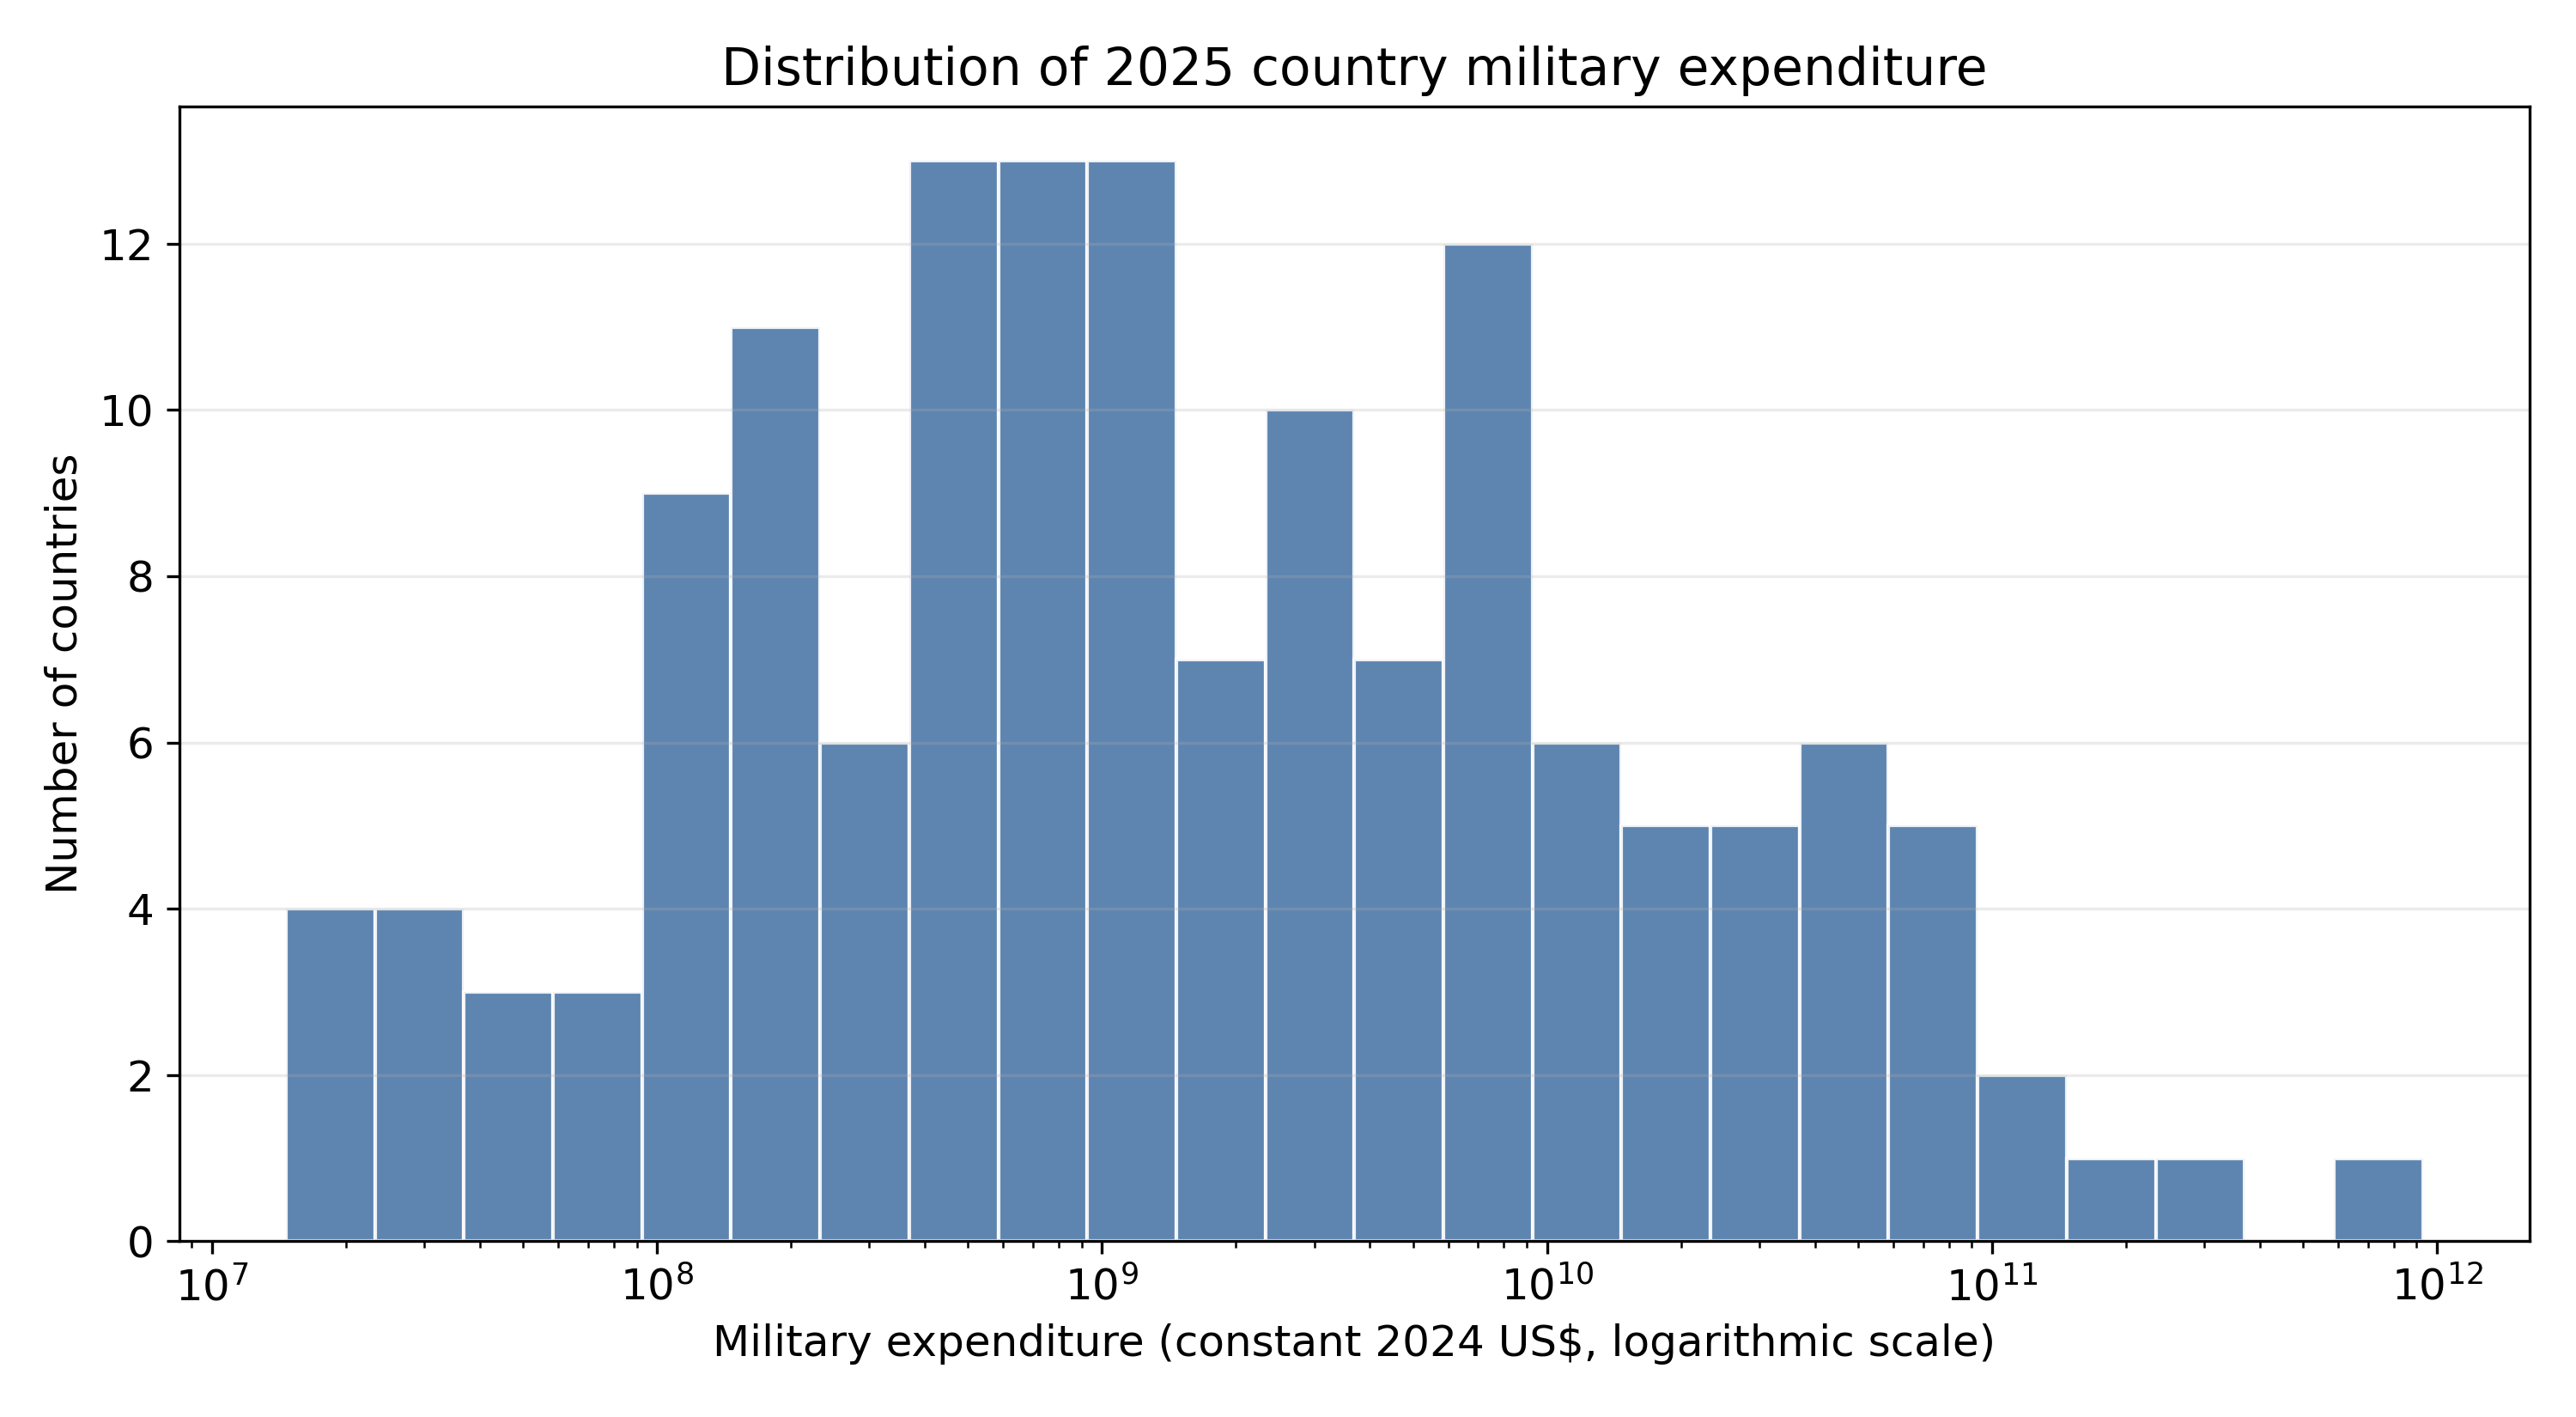

In [168]:
chart_records = df[
    included_mask & df["year_int"].eq(2025)
]

print(
    "Zero-expenditure records omitted from the logarithmic chart:",
    int(chart_records["spending_numeric"].eq(0).sum())
)
zero_entities = chart_records.loc[
    chart_records["spending_numeric"].eq(0), "Entity"
].tolist()
print("Zero-expenditure entities:", ", ".join(zero_entities))

create_distribution_chart(df, OUTPUT_CHART)

print(f"Chart saved to: {OUTPUT_CHART.resolve()}")
display(Image(filename=str(OUTPUT_CHART)))

## 12. Plain-language interpretation

The following paragraph is populated from calculated results.
It does not substitute presentation figures for observed values.

In [169]:
invalid_years = validation_summary['invalid_year_rows']
invalid_spending = validation_summary['invalid_spending_rows']
duplicate_country_years = validation_summary['duplicate_country_year_rows']
zero_count = int(chart_records["spending_numeric"].eq(0).sum())

print(
    f"For this run, the program reviewed {validation_summary['total_rows']:,} "
    f"records and detected {invalid_years:,} invalid year values, "
    f"{invalid_spending:,} invalid spending values, and "
    f"{duplicate_country_years:,} duplicate country-year entries under "
    f"its validation rules. It excluded "
    f"{validation_summary['aggregate_rows']:,} aggregate or unclassified "
    f"records from country analysis. For 2025, "
    f"{int(stats['country_count'])} eligible country observations had "
    f"average expenditure of approximately "
    f"${stats['mean'] / 1e9:,.3f} billion and a median of "
    f"${stats['median'] / 1e9:,.3f} billion. {zero_count} "
    f"zero-expenditure observations are included in those statistics but "
    f"omitted from the "
    f"logarithmic histogram. Worldwide expenditure increased by "
    f"{growth['percent_growth']:.2f}% between "
    f"{int(growth['first_year'])} and {int(growth['last_year'])}, "
    f"equivalent to compound annual growth of "
    f"{growth['cagr'] * 100:.2f}%."
)

For this run, the program reviewed 9,112 records and detected 0 invalid year values, 0 invalid spending values, and 0 duplicate country-year entries under its validation rules. It excluded 771 aggregate or unclassified records from country analysis. For 2025, 150 eligible country observations had average expenditure of approximately $18.266 billion and a median of $1.285 billion. 3 zero-expenditure observations are included in those statistics but omitted from the logarithmic histogram. Worldwide expenditure increased by 57.47% between 1988 and 2025, equivalent to compound annual growth of 1.23%.


## 13. Limitations and review checklist

- Verify source units, price basis, data vintage, and year coverage.
- The code-pattern heuristic is not an authoritative country classification.
- Missing or nonstandard codes can exclude otherwise usable countries.
- Country duplicate checks use entity names rather than a verified identifier.
- Duplicate country-year groups are excluded, not reconciled.
- Duplicate World years retain the last valid input record and require review.
- No missing annual values are invented or interpolated.
- Endpoint CAGR does not describe year-to-year volatility or imply causation.
- These checks cannot identify carried-forward or estimated observations
  unless the source provides suitable metadata.
- Validation confirms selected structural properties; it does not independently
  establish that source expenditure figures are accurate.